In [1]:
import kagglehub
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Download latest version
path = kagglehub.dataset_download("dylanjcastillo/7k-books-with-metadata")
print("Path to dataset files:", path)

books = pd.read_csv(f"{path}/books.csv")
books

Path to dataset files: C:\Users\LENOVO\.cache\kagglehub\datasets\dylanjcastillo\7k-books-with-metadata\versions\3


,isbn13,isbn10,title,subtitle,authors,categories,thumbnail,description,published_year,average_rating,num_pages,ratings_count
0,9780002005883,0002005883,Gilead,NaN,Marilynne Robinson,Fiction,http://books.google.com/books/content?id=KQZCP...,A NOVEL THAT READERS and critics have been eag...,2004.0,3.85,247.0,361.0
1,9780002261982,0002261987,Spider's Web,A Novel,Charles Osborne;Agatha Christie,Detective and mystery stories,http://books.google.com/books/content?id=gA5GP...,A new 'Christie for Christmas' -- a full-lengt...,2000.0,3.83,241.0,5164.0
2,9780006163831,0006163831,The One Tree,NaN,Stephen R. Donaldson,American fiction,http://books.google.com/books/content?id=OmQaw...,Volume Two of Stephen Donaldson's acclaimed se...,1982.0,3.97,479.0,172.0
3,9780006178736,0006178731,Rage of angels,NaN,Sidney Sheldon,Fiction,http://books.google.com/books/content?id=FKo2T...,"A memorable, mesmerizing heroine Jennifer -- b...",1993.0,3.93,512.0,29532.0
4,9780006280897,0006280897,The Four Loves,NaN,Clive Staples Lewis,Christian life,http://books.google.com/books/content?id=XhQ5X...,Lewis' work on the nature of love divides love...,2002.0,4.15,170.0,33684.0
...,...,...,...,...,...,...,...,...,...,...,...,...
6805,9788185300535,8185300534,I Am that,Talks with Sri Nisargadatta Maharaj,Sri Nisargadatta Maharaj;Sudhakar S. Dikshit,Philosophy,http://books.google.com/books/content?id=Fv_JP...,This collection of the timeless teachings of o...,1999.0,4.51,531.0,104.0
6806,9788185944609,8185944601,Secrets Of The Heart,NaN,Khalil Gibran,Mysticism,http://books.google.com/books/content?id=XcrVp...,NaN,1993.0,4.08,74.0,324.0
6807,9788445074879,8445074873,Fahrenheit 451,NaN,Ray Bradbury,Book burning,NaN,NaN,2004.0,3.98,186.0,5733.0
6808,9789027712059,9027712050,The Berlin Phenomenology,NaN,Georg Wilhelm Friedrich Hegel,History,http://books.google.com/books/content?id=Vy7Sk...,Since the three volume edition ofHegel's Philo...,1981.0,0.00,210.0,0.0


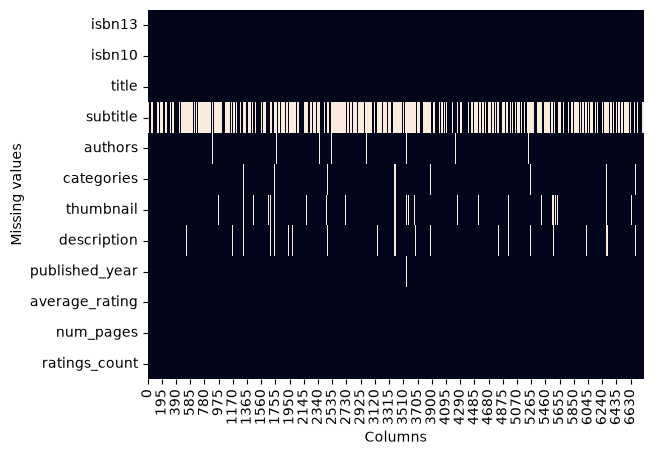

In [2]:
ax = plt.axes()
sns.heatmap(books.isna().transpose(), cbar=False, ax=ax)

plt.xlabel("Columns")
plt.ylabel("Missing values")

plt.show()

In [3]:
import numpy as np

books["missing_description"] = np.where(books["description"].isna(), 1, 0)
books["age_of_book"] = 2024 - books["published_year"]


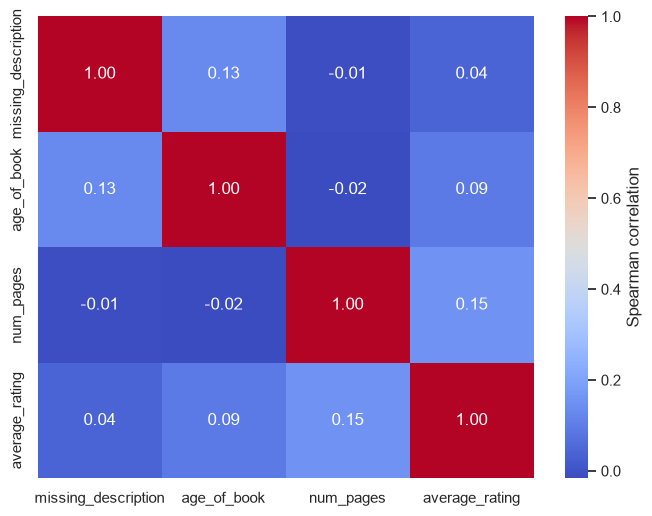

In [4]:
columns_of_interest = ["missing_description", "age_of_book", "num_pages", "average_rating"]

correlation_matrix = books[columns_of_interest].corr("spearman")

sns.set_theme(style="white")
plt.figure(figsize=(8, 6))
heatmap = sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", cbar_kws={"label": "Spearman correlation"})
plt.show()

In [5]:
# --- Data cleaning & feature engineering ---
book_missing = books[~(books["description"].isna())].copy()
book_missing["age_of_book"] = 2024 - book_missing["published_year"]
book_missing["words_in_description"] = book_missing["description"].str.split().str.len()

print(f"Before filtering: {len(book_missing)} books")

# Keep only books with a reasonably detailed description (5-40 words)
book_missing = book_missing[book_missing["words_in_description"].between(5, 40)]

# Drop rows with missing numeric features
book_missing = book_missing.dropna(subset=["published_year", "average_rating", "num_pages"])

print(f"After filtering: {len(book_missing)} books")

# Combine title and subtitle
book_missing["title_and_subtitle"] = np.where(
    book_missing["subtitle"].isna(),
    book_missing["title"],
    book_missing["title"].astype(str) + ": " + book_missing["subtitle"].astype(str)
)

# Tag description with isbn13 so we can trace back the recommended results
book_missing["tagged_description"] = book_missing["isbn13"].astype(str) + " " + book_missing["description"].astype(str)

book_missing.head()


Before filtering: 6548 books
After filtering: 3310 books


,isbn13,isbn10,title,subtitle,authors,categories,thumbnail,description,published_year,average_rating,num_pages,ratings_count,missing_description,age_of_book,words_in_description,title_and_subtitle,tagged_description
2,9780006163831,0006163831,The One Tree,NaN,Stephen R. Donaldson,American fiction,http://books.google.com/books/content?id=OmQaw...,Volume Two of Stephen Donaldson's acclaimed se...,1982.0,3.97,479.0,172.0,0,42.0,14,The One Tree,9780006163831 Volume Two of Stephen Donaldson'...
9,9780006472612,0006472613,Master of the Game,NaN,Sidney Sheldon,Adventure stories,http://books.google.com/books/content?id=TkTYp...,Kate Blackwell is an enigma and one of the mos...,1982.0,4.11,489.0,43540.0,0,42.0,30,Master of the Game,9780006472612 Kate Blackwell is an enigma and ...
10,9780006479673,0006479677,If Tomorrow Comes,NaN,Sidney Sheldon,Adventure stories,http://books.google.com/books/content?id=l2tBi...,One of Sidney Sheldon's most popular and bests...,1994.0,4.04,501.0,49170.0,0,30.0,18,If Tomorrow Comes,9780006479673 One of Sidney Sheldon's most pop...
14,9780006483892,0006483895,Murder in LaMut,NaN,Raymond E. Feist;Joel Rosenberg,Adventure stories,http://books.google.com/books/content?id=I2jbB...,"Available in the U.S. for the first time, this...",2003.0,3.70,337.0,5083.0,0,21.0,29,Murder in LaMut,9780006483892 Available in the U.S. for the fi...
20,9780006496892,000649689X,Glittering Images,NaN,Susan Howatch,English fiction,http://books.google.com/books/content?id=rDHbn...,"It is 1937, and Charles Ashworth, a Canon to t...",1996.0,4.07,512.0,2045.0,0,28.0,33,Glittering Images,"9780006496892 It is 1937, and Charles Ashworth..."


In [6]:
# --- Build vector database with ChromaDB (ONNX MiniLM embeddings) ---
import chromadb
from chromadb.utils import embedding_functions

embedding_function = embedding_functions.DefaultEmbeddingFunction()

client = chromadb.PersistentClient(path="chroma_books")

# Reuse the existing collection if it is already populated, otherwise rebuild it
existing_names = [c.name for c in client.list_collections()]
needs_rebuild = True
if "books" in existing_names:
    try:
        if client.get_collection("books").count() > 0:
            books_db = client.get_collection("books", embedding_function=embedding_function)
            needs_rebuild = False
    except Exception:
        pass

if needs_rebuild:
    try:
        client.delete_collection("books")
    except Exception:
        pass
    books_db = client.create_collection(name="books", embedding_function=embedding_function)

    # Add in smaller batches so we can show progress and restart if needed
    docs = book_missing["tagged_description"].tolist()
    ids = [str(int(isbn)) for isbn in book_missing["isbn13"]]
    batch_size = 200
    for i in range(0, len(docs), batch_size):
        books_db.add(documents=docs[i:i + batch_size], ids=ids[i:i + batch_size])
        print(f"indexed {min(i + batch_size, len(docs))}/{len(docs)} documents")

print(f"Collection 'books' ready with {books_db.count()} documents")


Collection 'books' ready with 3310 documents


In [7]:
# --- Semantic retrieval ---
def retrieve_semantic_recommendations(query, isbns_db, top_k=10):
    recs = isbns_db.query(query_texts=[query], n_results=40)
    rec_list = [int(isbn) for isbn in recs["ids"][0]]

    semantic_books = book_missing[book_missing["isbn13"].isin(rec_list)].set_index("isbn13")
    semantic_books = semantic_books.reindex(rec_list)

    top_books = semantic_books.sort_values("average_rating", ascending=False).head(top_k)
    return top_books[["title_and_subtitle", "authors", "categories", "average_rating", "description"]]


def recommend_books(query):
    return retrieve_semantic_recommendations(query, books_db, top_k=5)


recommend_books("Books about space exploration")


,title_and_subtitle,authors,categories,average_rating,description
isbn13,,,,,
9780789410245,Stephen Biesty's Incredible Explosions,Stephen Biesty;Richard Platt,Design,4.43,Text and cross-section illustrations present i...
9780739410127,Hitchhiker's Trilogy,Douglas Adams,"Dent, Arthur (Fictitious character)",4.40,Chronicles the off-beat and occasionally extra...
9780586203798,Mistress of the Empire,Raymond E. Feist;Janny Wurts,English fiction,4.31,Book 3 of the Empire trilogy.
9781590300060,The Wave in the Mind: Talks and Essays on the ...,Ursula K. Le Guin,Literary Collections,4.28,The author presents a collection of nonfiction...
9780670876129,The Adventures of Pippi Longstocking,Astrid Lindgren;Michael Chesworth,Juvenile Fiction,4.25,A collection of three previously published boo...


In [8]:
# --- Simplify book categories ---
category_map = {
    "Science Fiction": ["science fiction", "sci-fi", "dystopia", "space"],
    "Fantasy": ["fantasy", "magic", "dragon", "sword"],
    "Mystery & Thriller": ["detective", "mystery", "thriller", "crime", "suspense", "horror"],
    "Romance": ["romance", "love stories"],
    "History & Politics": ["history", "politic", "government", "war", "military", "democracy"],
    "Biography & Memoir": ["biography", "autobiography", "memoir"],
    "Philosophy": ["philosophy", "philosophic", "ethics", "logic"],
    "Religion & Spirituality": ["religion", "christian", "bible", "spiritual", "buddh", "hindu", "islam", "mysticism", "theology"],
    "Science & Technology": ["science", "physics", "biology", "astronomy", "chemistry", "math", "computer", "engineer", "technology", "medicine"],
    "Psychology": ["psychology", "mind", "cognitive", "emotion"],
    "Self-Help": ["self-help", "self help", "motivation", "happiness", "habit", "success"],
    "Business & Economics": ["business", "economics", "economic", "finance", "money", "market", "investment", "management"],
    "Fiction": ["fiction", "novel", "stories", "saga", "poetry", "literary", "comedy", "drama"],
    "Nonfiction": ["nonfiction", "education", "sociology", "essays", "reference", "guide", "art", "cooking", "travel", "nature"],
}


def simplfy_category(raw_category):
    if not isinstance(raw_category, str):
        return ""
    c = raw_category.lower()
    for bucket, keywords in category_map.items():
        if any(k in c for k in keywords):
            return bucket
    return ""


book_missing["simplified_category"] = book_missing["categories"].apply(simplfy_category)
print(book_missing["simplified_category"].value_counts())


simplified_category
Fiction                    2148
                            295
Biography & Memoir          220
Nonfiction                  152
History & Politics          148
Science & Technology         91
Religion & Spirituality      64
Philosophy                   63
Business & Economics         39
Psychology                   38
Self-Help                    16
Mystery & Thriller           16
Fantasy                      13
Science Fiction               6
Romance                       1
Name: count, dtype: int64


In [9]:
# --- Tone classification (keyword scoring) ---
tone_keywords = {
    "Happy": ["joy", "happy", "delight", "laugh", "celebration", "cheer", "witty", "humor", "fun"],
    "Suspenseful": ["suspense", "tension", "secrets", "deception", "mystery", "hidden", "betrayal"],
    "Thrilling": ["thrill", "chase", "danger", "revenge", "murder", "kill", "escape", "battle", "war"],
    "Mysterious": ["secret", "enigma", "curious", "shadow", "strange", "ghost", "riddle", "lost"],
    "Sad": ["grief", "loss", "dying", "death", "tragedy", "sorrow", "heartbreak", "alone"],
}


def classify_tone(text):
    text = text.lower()
    scores = {tone: sum(word in text for word in words) for tone, words in tone_keywords.items()}
    best_tone = max(scores, key=scores.get)
    return best_tone if scores[best_tone] > 0 else ""


book_missing["tone"] = book_missing["description"].apply(classify_tone)
print(book_missing["tone"].value_counts())


tone
               2278
Thrilling       548
Happy           148
Mysterious      128
Sad             115
Suspenseful      93
Name: count, dtype: int64


In [10]:
# --- Recommendation dashboard ---
import gradio as gr


def recommend_dashboard(query, selected_category, selected_tone, top_k):
    query_k = max(top_k * 5, 40)
    recs = books_db.query(query_texts=[query], n_results=query_k)
    rec_list = [int(isbn) for isbn in recs["ids"][0]]

    filtered = book_missing[book_missing["isbn13"].isin(rec_list)].copy()
    filtered["_rank"] = filtered["isbn13"].apply(lambda x: rec_list.index(x))
    filtered = filtered.sort_values("_rank")

    # Apply each filter, but keep the wider set when a filter empties the results
    if selected_category != "Any":
        hits = filtered[filtered["simplified_category"] == selected_category]
        if not hits.empty:
            filtered = hits
    if selected_tone != "Any":
        hits = filtered[filtered["tone"] == selected_tone]
        if not hits.empty:
            filtered = hits

    top_books = filtered.head(top_k)
    return top_books[["title_and_subtitle", "authors", "categories", "average_rating", "description"]]


categories_dropdown = ["Any"] + list(category_map.keys())
tones = ["Any"] + list(tone_keywords.keys())

dashboard = gr.Interface(
    fn=recommend_dashboard,
    inputs=[
        gr.Textbox(label="What are you in the mood for?", placeholder="e.g. space exploration, love story..."),
        gr.Dropdown(choices=categories_dropdown, value="Any", label="Category"),
        gr.Dropdown(choices=tones, value="Any", label="Tone"),
        gr.Slider(minimum=3, maximum=20, step=1, value=8, label="Number of recommendations"),
    ],
    outputs=gr.DataFrame(
        headers=["Title", "Authors", "Category", "Rating", "Description"],
        wrap=True,
        label="Recommended books",
    ),
    title="LLM Books Recommendation",
    description="Semantic book recommender: describe what you feel like reading.",
)

dashboard.launch(share=False, inbrowser=True)


* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


Created dataset file at: .gradio\flagged\dataset1.csv
